# Luanda Cost of Living and Household Pressure Analysis (2014–2024)

## Project Background

This notebook presents an analytical view of household economic pressure in Luanda, Angola, from 2014 to 2024.

The analysis focuses on the relationship between average household income and the cost of essential living items such as rent, food, transport, utilities, education, and health-related expenses.

## Objective

The objective of this project is to estimate how the cost of essential living has evolved over time and to assess whether average income has kept pace with household needs.

## Methodology

This notebook combines:
- a modeled household budget in Angolan Kwanza (Kz), built for analytical purposes;
- broader socioeconomic reference indicators used only as context.

The household budget series is a realistic analytical model for Luanda and should be interpreted as an estimation framework, not as an official household survey microdata series.

## Why this matters

Understanding the gap between income and essential living costs helps illustrate the economic pressure faced by many families in Luanda and supports evidence-based social discussion.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:,.0f}'.format

data = {
    'Year': [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024],
    'Avg_Household_Income_Kz': [55000, 60000, 68000, 78000, 95000, 110000, 125000, 145000, 180000, 220000, 260000],
    'Rent_Kz': [35000, 40000, 47000, 55000, 70000, 85000, 100000, 120000, 170000, 220000, 280000],
    'Food_Kz': [45000, 52000, 60000, 70000, 85000, 100000, 120000, 145000, 200000, 260000, 340000],
    'Transport_Kz': [12000, 14000, 16000, 18000, 22000, 28000, 35000, 42000, 60000, 80000, 110000],
    'Utilities_Kz': [8000, 9000, 10000, 12000, 15000, 18000, 22000, 26000, 35000, 45000, 60000],
    'Education_Health_Kz': [10000, 12000, 15000, 18000, 22000, 26000, 32000, 38000, 52000, 70000, 95000],
    'Other_Basic_Kz': [7000, 8000, 9000, 11000, 14000, 17000, 20000, 24000, 32000, 42000, 55000],
    'Under5_Mortality_Angola_per_1000': [109, 105, 101, 97, 92, 87, 82, 77, 72, 64, 60]
}

df = pd.DataFrame(data)

df['Total_Basic_Cost_Kz'] = (
    df['Rent_Kz'] +
    df['Food_Kz'] +
    df['Transport_Kz'] +
    df['Utilities_Kz'] +
    df['Education_Health_Kz'] +
    df['Other_Basic_Kz']
)

df['Monthly_Gap_Kz'] = df['Avg_Household_Income_Kz'] - df['Total_Basic_Cost_Kz']
df['Coverage_Ratio'] = (df['Avg_Household_Income_Kz'] / df['Total_Basic_Cost_Kz']).round(2)

df

,Year,Avg_Household_Income_Kz,Rent_Kz,Food_Kz,Transport_Kz,Utilities_Kz,Education_Health_Kz,Other_Basic_Kz,Under5_Mortality_Angola_per_1000,Total_Basic_Cost_Kz,Monthly_Gap_Kz,Coverage_Ratio
0,2014,55000,35000,45000,12000,8000,10000,7000,109,117000,-62000,0
1,2015,60000,40000,52000,14000,9000,12000,8000,105,135000,-75000,0
2,2016,68000,47000,60000,16000,10000,15000,9000,101,157000,-89000,0
3,2017,78000,55000,70000,18000,12000,18000,11000,97,184000,-106000,0
4,2018,95000,70000,85000,22000,15000,22000,14000,92,228000,-133000,0
5,2019,110000,85000,100000,28000,18000,26000,17000,87,274000,-164000,0
6,2020,125000,100000,120000,35000,22000,32000,20000,82,329000,-204000,0
7,2021,145000,120000,145000,42000,26000,38000,24000,77,395000,-250000,0
8,2022,180000,170000,200000,60000,35000,52000,32000,72,549000,-369000,0
9,2023,220000,220000,260000,80000,45000,70000,42000,64,717000,-497000,0


## Data Dictionary

- **Avg_Household_Income_Kz**: estimated average household monthly income in Kwanza.
- **Rent_Kz**: estimated monthly rent cost.
- **Food_Kz**: estimated monthly food basket cost.
- **Transport_Kz**: estimated monthly transport expenses.
- **Utilities_Kz**: estimated monthly expenses for water, electricity, and similar services.
- **Education_Health_Kz**: estimated monthly education and health-related expenses.
- **Other_Basic_Kz**: estimated monthly spending on other basic needs.
- **Total_Basic_Cost_Kz**: total monthly essential cost.
- **Monthly_Gap_Kz**: income minus total basic cost.
- **Coverage_Ratio**: proportion of essential costs covered by income.
- **Under5_Mortality_Angola_per_1000**: national under-5 mortality proxy used for broader social context.

In [2]:
df

,Year,Avg_Household_Income_Kz,Rent_Kz,Food_Kz,Transport_Kz,Utilities_Kz,Education_Health_Kz,Other_Basic_Kz,Under5_Mortality_Angola_per_1000,Total_Basic_Cost_Kz,Monthly_Gap_Kz,Coverage_Ratio
0,2014,55000,35000,45000,12000,8000,10000,7000,109,117000,-62000,0
1,2015,60000,40000,52000,14000,9000,12000,8000,105,135000,-75000,0
2,2016,68000,47000,60000,16000,10000,15000,9000,101,157000,-89000,0
3,2017,78000,55000,70000,18000,12000,18000,11000,97,184000,-106000,0
4,2018,95000,70000,85000,22000,15000,22000,14000,92,228000,-133000,0
5,2019,110000,85000,100000,28000,18000,26000,17000,87,274000,-164000,0
6,2020,125000,100000,120000,35000,22000,32000,20000,82,329000,-204000,0
7,2021,145000,120000,145000,42000,26000,38000,24000,77,395000,-250000,0
8,2022,180000,170000,200000,60000,35000,52000,32000,72,549000,-369000,0
9,2023,220000,220000,260000,80000,45000,70000,42000,64,717000,-497000,0


In [3]:
df.describe()

,Year,Avg_Household_Income_Kz,Rent_Kz,Food_Kz,Transport_Kz,Utilities_Kz,Education_Health_Kz,Other_Basic_Kz,Under5_Mortality_Angola_per_1000,Total_Basic_Cost_Kz,Monthly_Gap_Kz,Coverage_Ratio
count,11,11,11,11,11,11,11,11,11,11,11,11
mean,"2,019","126,909","111,091","134,273","39,727","23,636","35,455","21,727",86,"365,909","-239,000",0
std,3,"68,076","80,331","95,267","31,490","16,741","26,875","15,480",17,"266,092","198,637",0
min,"2,014","55,000","35,000","45,000","12,000","8,000","10,000","7,000",60,"117,000","-680,000",0
25%,"2,016","73,000","51,000","65,000","17,000","11,000","16,500","10,000",74,"170,500","-309,500",0
50%,"2,019","110,000","85,000","100,000","28,000","18,000","26,000","17,000",87,"274,000","-164,000",0
75%,"2,022","162,500","145,000","172,500","51,000","30,500","45,000","28,000",99,"472,000","-97,500",0
max,"2,024","260,000","280,000","340,000","110,000","60,000","95,000","55,000",109,"940,000","-62,000",0


## Household Budget Pressure

The central question in this notebook is whether average household income is enough to cover essential monthly living costs.

A negative monthly gap indicates that a family would struggle to cover basic needs without informal coping mechanisms, debt, support networks, or significant reductions in consumption.

In [4]:
df[['Year', 'Avg_Household_Income_Kz', 'Total_Basic_Cost_Kz', 'Monthly_Gap_Kz', 'Coverage_Ratio']]

,Year,Avg_Household_Income_Kz,Total_Basic_Cost_Kz,Monthly_Gap_Kz,Coverage_Ratio
0,2014,55000,117000,-62000,0
1,2015,60000,135000,-75000,0
2,2016,68000,157000,-89000,0
3,2017,78000,184000,-106000,0
4,2018,95000,228000,-133000,0
5,2019,110000,274000,-164000,0
6,2020,125000,329000,-204000,0
7,2021,145000,395000,-250000,0
8,2022,180000,549000,-369000,0
9,2023,220000,717000,-497000,0


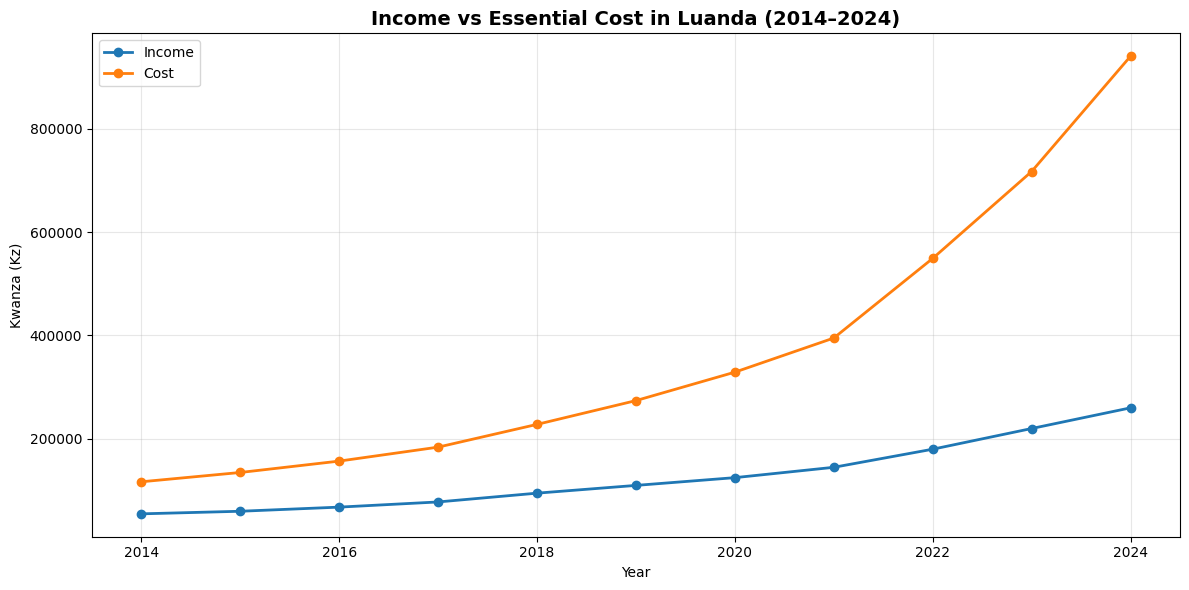

In [5]:
plt.figure(figsize=(12, 6))

plt.plot(df['Year'], df['Avg_Household_Income_Kz'], marker='o', linewidth=2, label='Income')
plt.plot(df['Year'], df['Total_Basic_Cost_Kz'], marker='o', linewidth=2, label='Cost')

plt.title('Income vs Essential Cost in Luanda (2014–2024)', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Kwanza (Kz)')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Interpretation: Income vs Essential Cost

The chart suggests that essential living costs increased much faster than household income over the period under analysis.

This indicates growing household pressure and a widening affordability challenge, especially in the later years of the series.

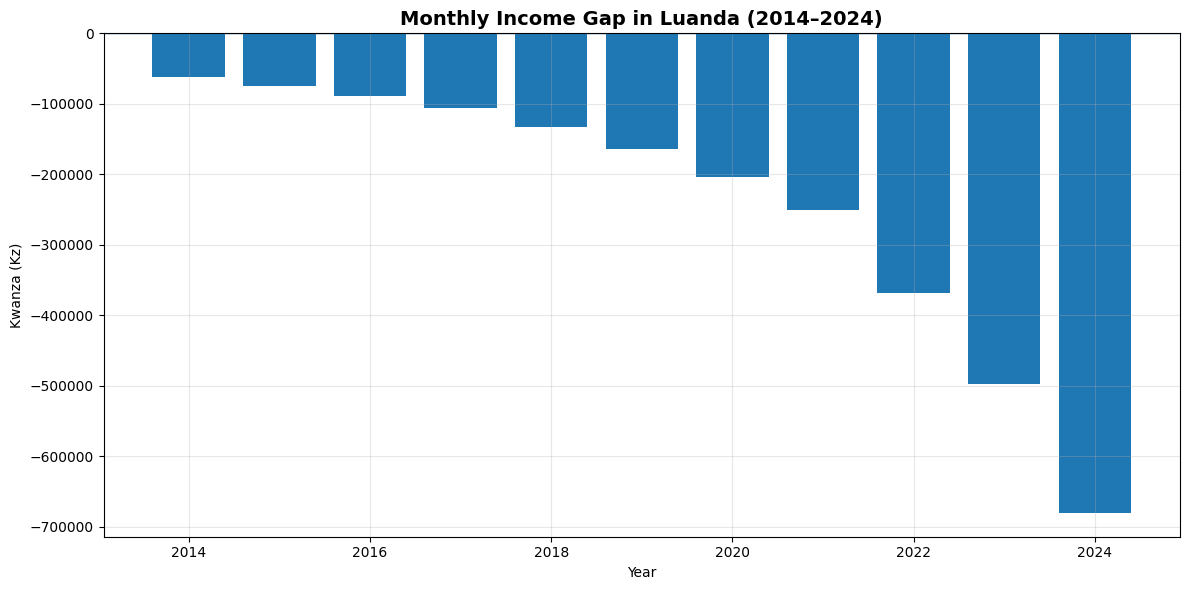

In [6]:
plt.figure(figsize=(12, 6))

plt.bar(df['Year'], df['Monthly_Gap_Kz'])

plt.title('Monthly Income Gap in Luanda (2014–2024)', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Kwanza (Kz)')

plt.axhline(0, linewidth=1)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Interpretation: Monthly Gap

When the monthly gap is below zero, it means household income is not enough to cover essential expenses.

This pattern may help explain why many families face persistent financial stress, reduced consumption capacity, and vulnerability to price shocks.

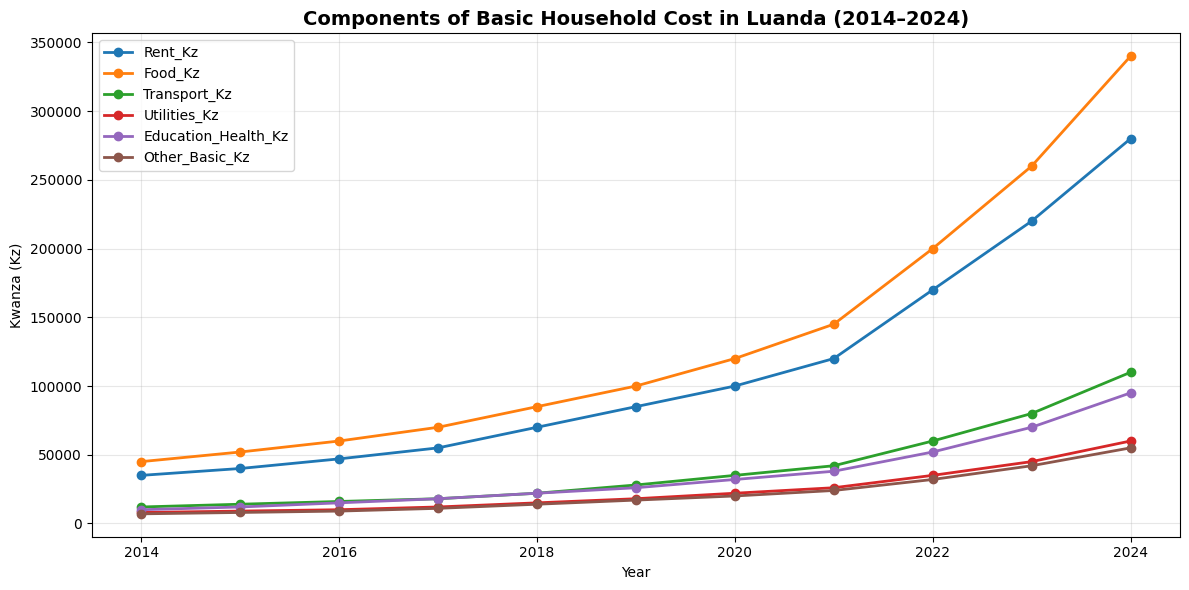

In [7]:
cost_columns = ['Rent_Kz', 'Food_Kz', 'Transport_Kz', 'Utilities_Kz', 'Education_Health_Kz', 'Other_Basic_Kz']

df.set_index('Year')[cost_columns].plot(figsize=(12, 6), marker='o', linewidth=2)

plt.title('Components of Basic Household Cost in Luanda (2014–2024)', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Kwanza (Kz)')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Cost Composition

Food and rent appear as the largest components of the household budget. Their growth over time suggests that basic survival costs place the greatest burden on families.

Transport, utilities, and education/health costs also rise, reinforcing the cumulative pressure on household budgets.

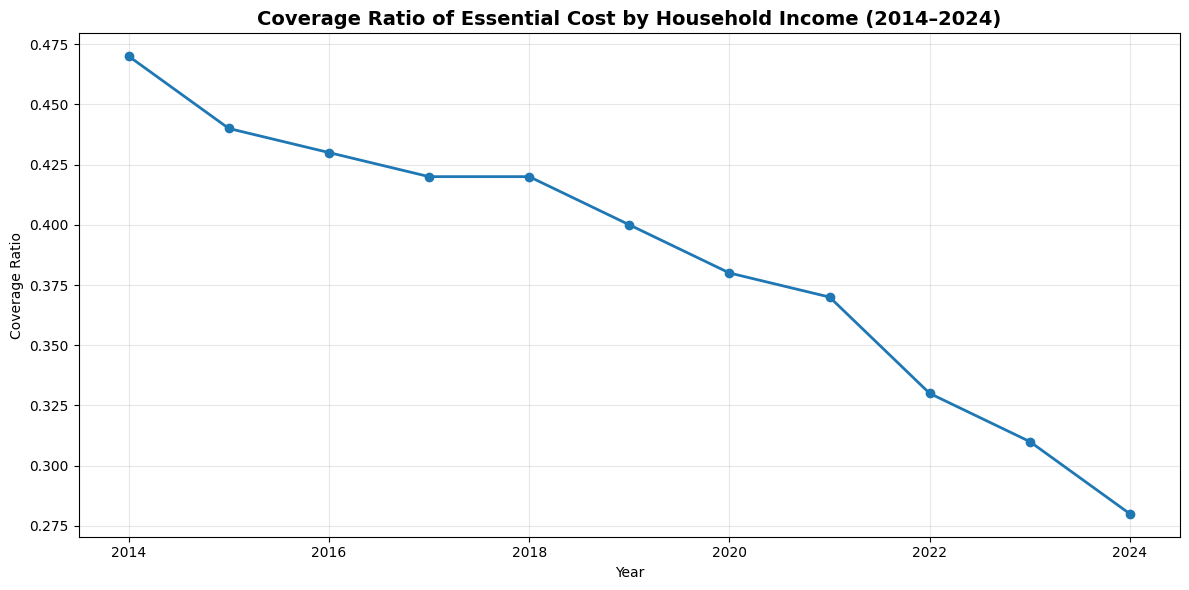

In [8]:
plt.figure(figsize=(12, 6))

plt.plot(df['Year'], df['Coverage_Ratio'], marker='o', linewidth=2)

plt.title('Coverage Ratio of Essential Cost by Household Income (2014–2024)', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Coverage Ratio')

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Interpretation: Coverage Ratio

A coverage ratio below 1 means average household income does not fully cover essential monthly needs.

The lower the ratio, the more severe the affordability problem. This metric provides a simple way to summarize household economic pressure over time.

## Broader Social Context

To complement the household budget analysis, this notebook includes a national under-5 mortality proxy for Angola.

This variable is not a Luanda-specific death count. Instead, it is used as a broader social context indicator, since long-run, city-level mortality series are harder to access consistently in public sources.

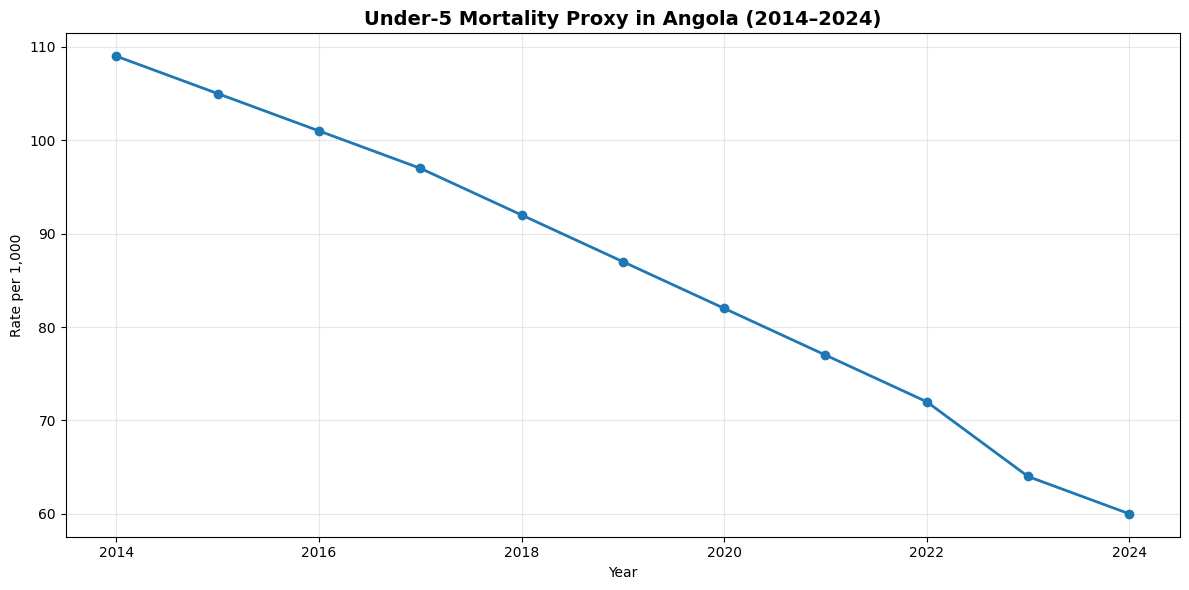

In [9]:
plt.figure(figsize=(12, 6))

plt.plot(df['Year'], df['Under5_Mortality_Angola_per_1000'], marker='o', linewidth=2)

plt.title('Under-5 Mortality Proxy in Angola (2014–2024)', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Rate per 1,000')

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Key Insight

Between 2014 and 2024, the gap between household income and essential cost widened significantly.

While income increased over time, it did not keep pace with the rapid rise in basic living costs.

By 2024, the average household covers less than one-third of essential expenses, suggesting severe affordability pressure.

## Limitations

This notebook does not claim to reproduce an official household survey for Luanda. The household budget values are analytical estimates built to model affordability pressure over time.

In addition, the mortality variable is national and is used only as a contextual social indicator, not as a direct measure of deaths in Luanda.

## Final Conclusion

This analysis highlights a critical affordability challenge in Luanda.

Over the past decade, essential living costs have increased at a significantly faster rate than household income. This has resulted in a growing financial gap, where many families may not be able to cover basic needs through income alone.

The declining coverage ratio reinforces the severity of the situation, indicating increasing reliance on alternative coping mechanisms such as informal income, family support, or reduced consumption.

This project demonstrates how data analysis can be used to model real-world socioeconomic challenges and provide structured insights into household financial pressure.

## Future Improvements

Future versions of this analysis could include:
- real CPI data from official Angolan sources;
- exchange rate adjustments;
- segmentation by income class;
- urban vs rural comparison;
- integration with survey data if available.

This would improve accuracy and allow for deeper socioeconomic insights.